# Heijunka (levelled) kit release with workcell setups

Copy of `phase2_assumptions_simulation.ipynb` that swaps the equal M860 → M970 → M1080 rotation for `release_mode="heijunka"` (README, Experiment 3). Everything else is unchanged: the station-group setup assumptions in [phase2_assumptions.md](phase2_assumptions.md), Year 3 resources, and the existing 75% setup reductions at stations 3, 4, 5, 8, and 11.

**Operational interpretation:**
- A workcell set means all parallel machines at one numbered station (for example, all six machines at 5-A), rather than all of Fabrication or Assembly.
- The complete station is set up once for **each product lot**, even when an earlier lot of that model was prepared. Setup happens when its first unit reaches the head of the station queue. Existing station work and maintenance finish first; all station machines are reserved during setup and while waiting for the setup team.
- Setup labor is `machine count × efficiency-adjusted setup time`. Elapsed setup is that labor divided by the assigned setup crew. Crew defaults to the station machine count; `SETUP_CREW` below overrides it. Operators come from the existing shared cell pools and are unavailable elsewhere while setting up. Crews are acquired atomically, in the pool's priority/FIFO order.
- A prepared lot remains ready at that station until it finishes. Its units can share machines with any other prepared product without further per-unit changeover setup. Zero setup inputs stay zero.
- **Arrivals (the change in this notebook):** one kit every 1.020 productive minutes, with no station lot gates or WIP cap, in a **deterministic level sequence weighted by each model's planned kit volume** (about 37% M860, 30% M970, 34% M1080 in Year 3). Before each kit, the model furthest behind its kit share is released, so every model's kits, and its good output, arrive at an even rate matching its own demand. The cyclic rotation instead gives each model one third of the kits.
- EOQ group identifiers retain the existing branch quantities, scrap planning, and component matching. They do not impose processing batches: matched assemblies leave immediately when their components are available.

These choices make the prose assumptions concrete. In particular, the station is unavailable during its group setup; prepared products may mix freely afterward. Part flow time starts at the oldest constituent kit's actual arrival; WIP counts component and assembly items.

## 1. Scenario inputs and setup crews

Change `YEAR` and `SETUP_CREW` here. This notebook uses the station-group setup policy throughout the detailed run. The tables show resources, product inputs, and elapsed setup times after efficiency and crew adjustment.

In [1]:
import os
import itertools
from dataclasses import replace
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lcd_sim.params import get_scenario, MODELS, STATIONS, STATION_INFO
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P

YEAR = 3
N_REPS = 10
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))
SETUP_CREW = {}   # e.g. {"5-A": 3}; default is one operator per machine at each station
sc = get_scenario(YEAR, release_mode="heijunka", setup_scope="workcell", setup_crew=SETUP_CREW)
print(f"Year {YEAR}; {sc.warmup_weeks}-week warm-up; {sc.run_weeks}-week measurement")
kits = sc.annual_kits()
print(f"Arrivals: heijunka level sequence; {sc.kit_interarrival_min:.4f} productive min/kit")
print("Kit shares: " + ", ".join(f"{m} {kits[m] / sum(kits.values()):.1%}" for m in MODELS))
print("First 30 kits:", " ".join(m[1:] for m in itertools.islice(sc.heijunka_sequence(), 30)))
print(f"Operators per shift: {sc.operators}")
station_inputs, product_inputs = sc.describe()
display(product_inputs)
display(station_inputs)
setup_inputs = pd.DataFrame([
    {"Station": ws, "Machines": sc.machines[ws],
     "Setup crew": sc.setup_crew.get(ws, sc.machines[ws]),
     **{f"{model} elapsed setup (min)": sc.machines[ws] * sc.op_times(model, ws)["setup"] / sc.setup_crew.get(ws, sc.machines[ws])
        if station_inputs.loc[ws, f"Time/part {model}"] > 0 else None for model in MODELS}}
    for ws in STATIONS
]).set_index("Station")
display(setup_inputs)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:,.3f}".format)

C:\Users\djhic\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


Year 3; 2-week warm-up; 8-week measurement
Arrivals: heijunka level sequence; 1.0197 productive min/kit
Kit shares: M860 37.1%, M970 29.5%, M1080 33.4%
First 30 kits: 860 1080 970 860 1080 970 860 1080 970 860 1080 970 860 1080 860 970 1080 860 970 1080 860 970 1080 860 970 1080 860 860 1080 970
Operators per shift: {'Fab': 7, 'Asm': 13}


,Demand,EOQ,Lots_per_year,Planned_yield,Sent to KIT (1-M),Sent to KB (4-A),Sent to DISP (2-M),Sent to PWR (3-A/5-A),Sent to BL (6-A),Sent to ASM (7-M/8-A/9-M/10-M/11-A/12-M),Kits_per_year,Sent to ASM (8-A/9-M/10-M/11-A/12-M)
Model,,,,,,,,,,,,
M860,63877,754,85,0.7832,963,915,963,954,897,888.0,81855,NaN
M970,55296,596,93,0.8528,699,671,699,696,665,NaN,65007,658.0
M1080,61516,655,94,0.8350,785,741,785,781,732,NaN,73790,725.0


,Description,Type,Cell,Machines,Efficiency,Time/part M860,Time/part M970,Time/part M1080,Setup M860,Setup M970,...,Qty/lot M970,Qty/lot M1080,Scrap factor M860,Scrap factor M970,Scrap factor M1080,PM_every_units,PM_min,MTBF_hr,Repair_min,Units_between_failures
Station,,,,,,,,,,,,,,,,,,,,,
1-M,Unpack and label components,M,Fab,2,0.90,1.742,1.851,2.287,16.67,0.00,...,699.0,785.0,1.2767,1.1726,1.1976,NaN,NaN,NaN,NaN,NaN
2-M,Sanitize LC displays and PCBs,M,Fab,2,0.95,1.135,1.548,1.651,21.05,0.00,...,699.0,785.0,1.2767,1.1726,1.1976,NaN,NaN,100.0,10.0,4199.0
3-A,Connect display to power strip,A,Fab,2,1.05,0.564,1.404,1.686,1.19,2.38,...,696.0,781.0,1.2640,1.1667,1.1916,12000.0,10.0,50.0,30.0,2526.0
4-A,Tack keyboard inputs to display,A,Fab,1,1.02,0.969,0.484,0.678,1.96,2.45,...,671.0,741.0,1.2132,1.1258,1.1304,12000.0,20.0,75.0,60.0,6179.0
5-A,Bond power strip to PCB and LCD,A,Fab,6,0.99,2.697,6.459,7.251,3.79,15.15,...,696.0,781.0,1.2387,1.1492,1.1761,12000.0,20.0,250.0,120.0,2813.0
6-A,Insert backlights and sensors,A,Fab,3,0.95,1.242,1.964,3.308,10.53,0.00,...,665.0,732.0,1.1886,1.1144,1.1167,6000.0,10.0,60.0,60.0,1678.0
7-M,Verify alignment and bonds,M,Fab,1,0.90,1.316,NaN,NaN,13.33,NaN,...,NaN,NaN,1.1768,NaN,NaN,NaN,NaN,100.0,15.0,4561.0
8-A,Power up test on components,A,Fab,2,0.95,1.350,1.556,2.074,2.63,2.63,...,658.0,725.0,1.1415,1.1033,1.1055,6000.0,10.0,250.0,90.0,9079.0
9-M,Solder subassemblies and connectors,M,Asm,6,0.93,3.372,7.272,8.642,5.38,0.00,...,658.0,725.0,1.0958,1.0702,1.0724,NaN,NaN,NaN,NaN,NaN


,Machines,Setup crew,M860 elapsed setup (min),M970 elapsed setup (min),M1080 elapsed setup (min)
Station,,,,,
1-M,2,2,16.666667,0.000000,0.000000
2-M,2,2,21.052632,0.000000,0.000000
3-A,2,2,1.190476,2.380952,2.857143
4-A,1,1,1.960784,2.450980,3.431373
5-A,6,6,3.787879,15.151515,16.414141
6-A,3,3,10.526316,0.000000,0.000000
7-M,1,1,13.333333,NaN,NaN
8-A,2,2,2.631579,2.631579,3.947368
9-M,6,6,5.376344,0.000000,0.000000


## 2. Plant flow and model checks

One replication illustrates the assumptions. Charts with a grey warm-up band include the initial two weeks; summary statistics use the following eight weeks. A station-group setup reserves every machine at that station. Prepared product lots can then share the station without per-unit changeover setup.

Accounting and operator checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.8859226332185367}


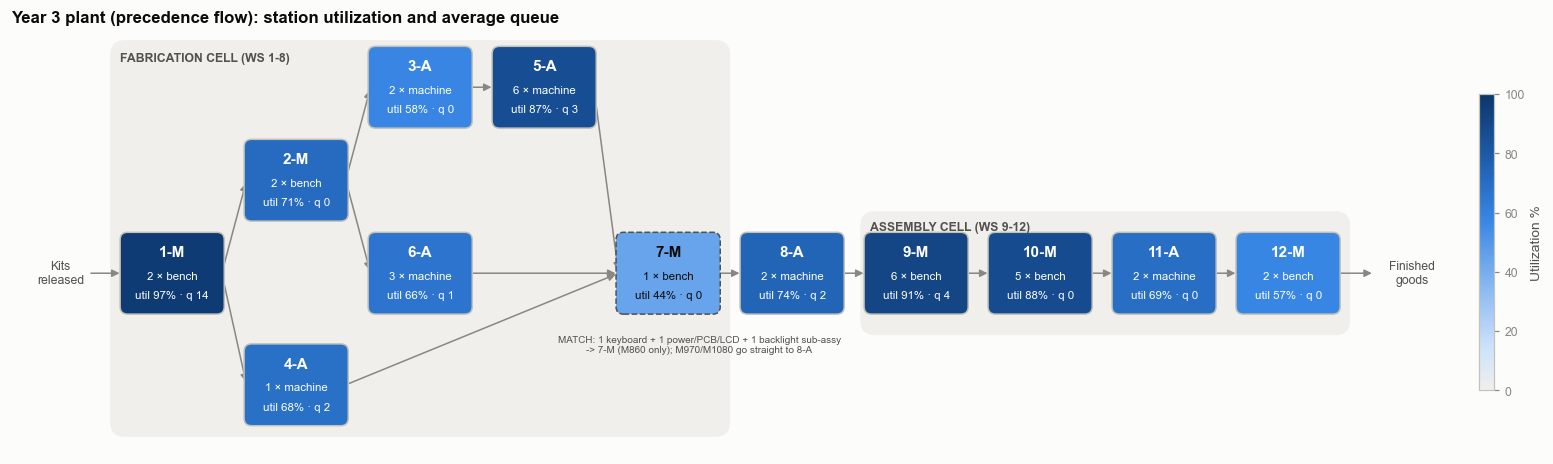

In [2]:
res = run(sc)
assert all(value == 0 for key, value in res.checks.items() if "must be 0" in key), res.checks
assert res.checks["max operator utilization (<= 1)"] <= 1 + 1e-9
assert (res.stations["Gate-blocked %"] == 0).all()
print("Accounting and operator checks:", res.checks)
P.plot_block_diagram(res); plt.show()


## 3. Throughput by product versus demand

Read each product separately. With the heijunka sequence, each model's kits arrive in proportion to its own kit volume, so each model's weekly output should sit close to its own dashed demand line. The remaining week-to-week variation comes from scrap, breakdowns, and maintenance, not from the release.

,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,"10,244.000","1,280.500","1,277.540",1.002,2.133,1.804
M970,"8,786.000","1,098.250","1,105.920",0.993,1.883,1.825
M1080,"9,782.000","1,222.750","1,230.320",0.994,2.266,1.971
Total,"28,812.000","3,601.500","3,613.780",0.997,2.102,1.881


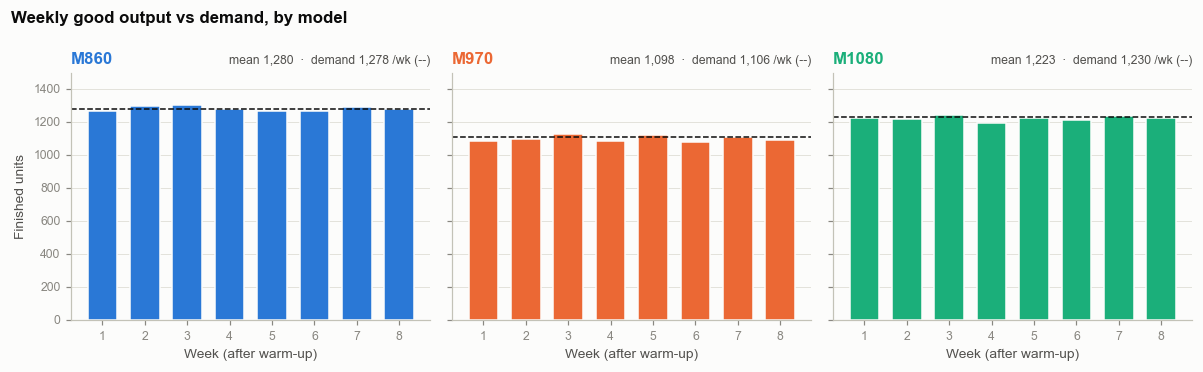

In [3]:
display(res.throughput)
P.plot_throughput(res); plt.show()


## 4. Queues, WIP, and matching

Daily station bars show waiting units by product; the detailed lines show the time pattern. No lot gates are used in this policy.

**Waiting at the match** is the component buffer after fabrication branches 4-A, 5-A, and 6-A. It is separate from station 7. One keyboard, one power/PCB/LCD, and one backlight subassembly from the same product lot must be available before an assembly moves to 7-M (M860) or directly to 8-A (M970/M1080). Waiting components count as WIP and occupy no operators or machines.

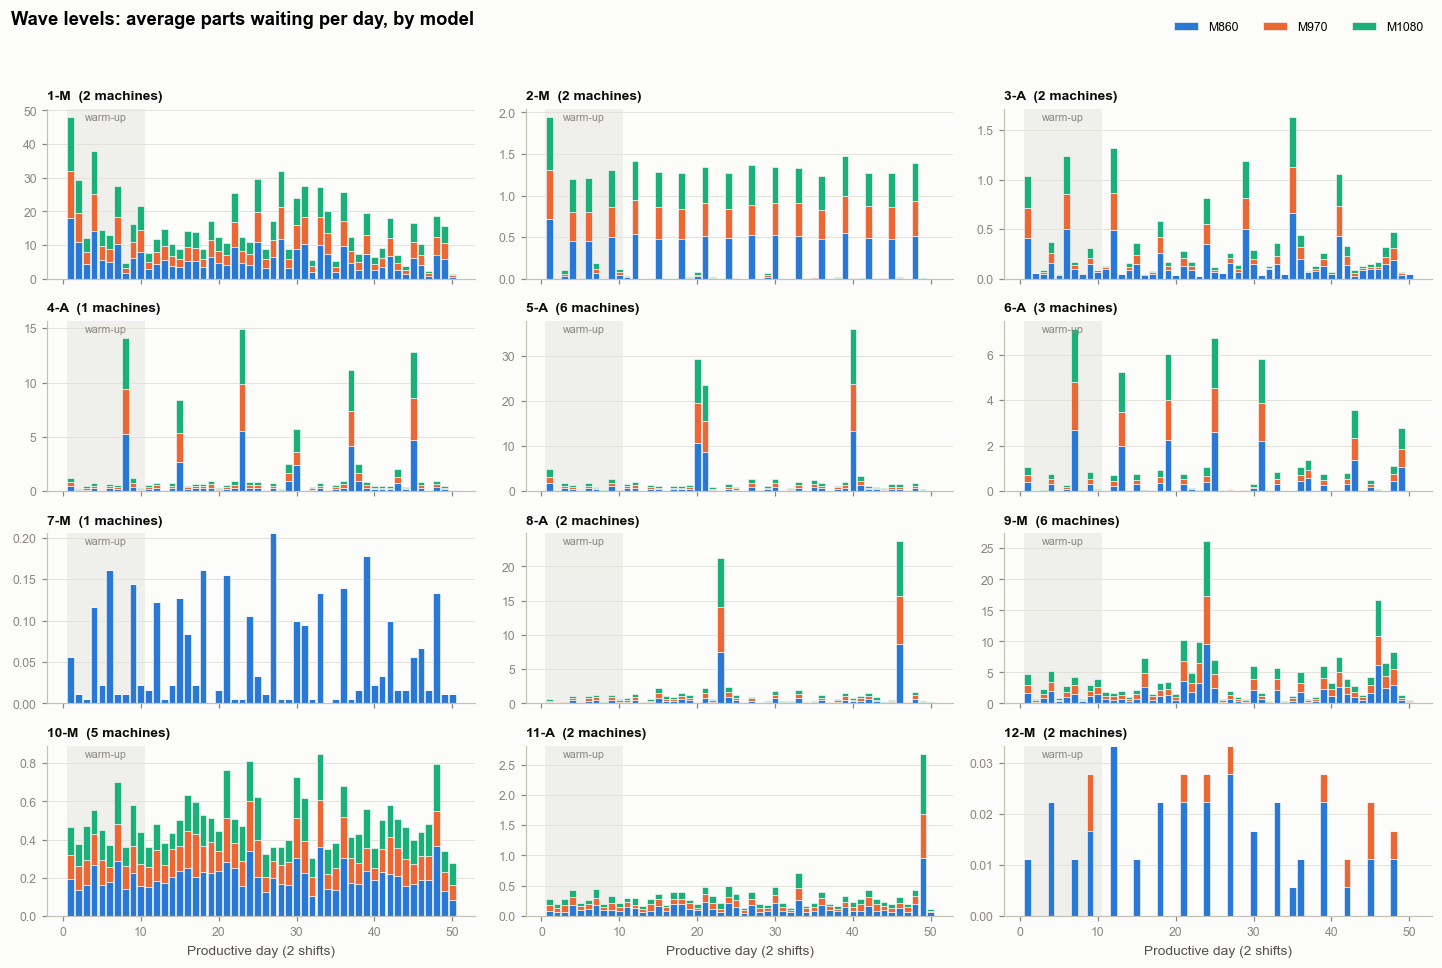

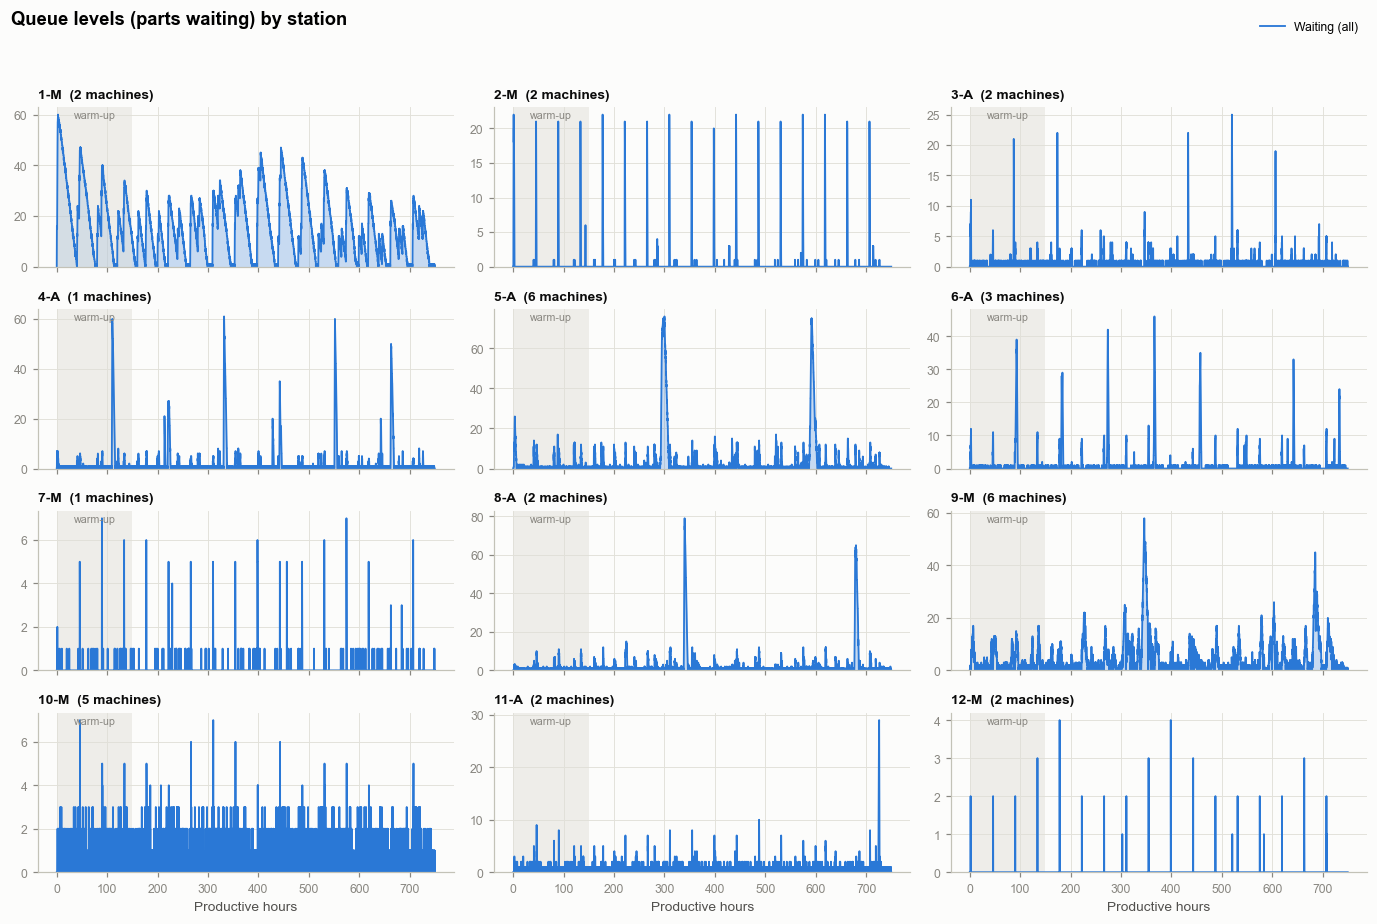

In [4]:
P.plot_wave_levels(res); plt.show()
P.plot_queue_lines(res, gated=False); plt.show()


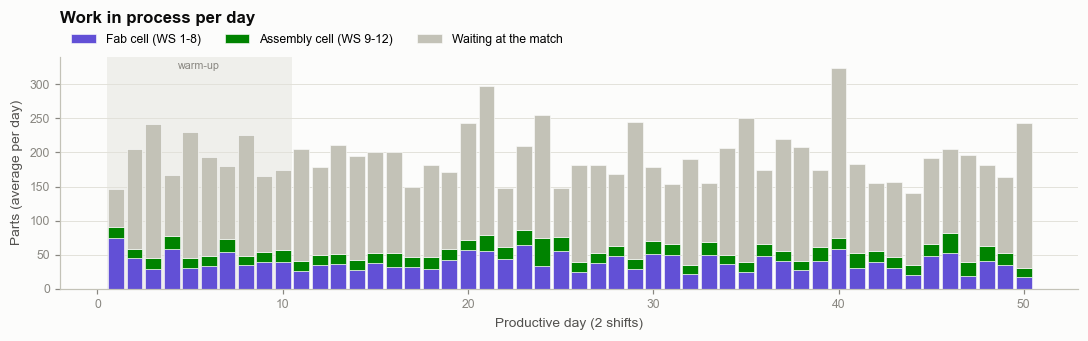

WIP near measurement start/end: 219 / 204 items
Net change: -15 items
Time-average WIP: 195.5 component/assembly items


In [5]:
P.plot_wip(res); plt.show()
window = res.trace[res.trace.t >= sc.warmup_min]
print(f"WIP near measurement start/end: {window.iloc[0]['WIP']:,.0f} / {window.iloc[-1]['WIP']:,.0f} items")
print(f"Net change: {window.iloc[-1]['WIP'] - window.iloc[0]['WIP']:,.0f} items")
print(f"Time-average WIP: {res.kpis['WIP|Average WIP (parts)']:,.1f} component/assembly items")


## 5. Station utilization and capacity

Utilization includes processing plus setup. The historical Phase 1 comparison and processing-only capacity estimates are reference values based on the original planned mix; the heijunka sequence uses that same planned kit mix. Capacity bars exclude setup, operator waiting, and downtime.

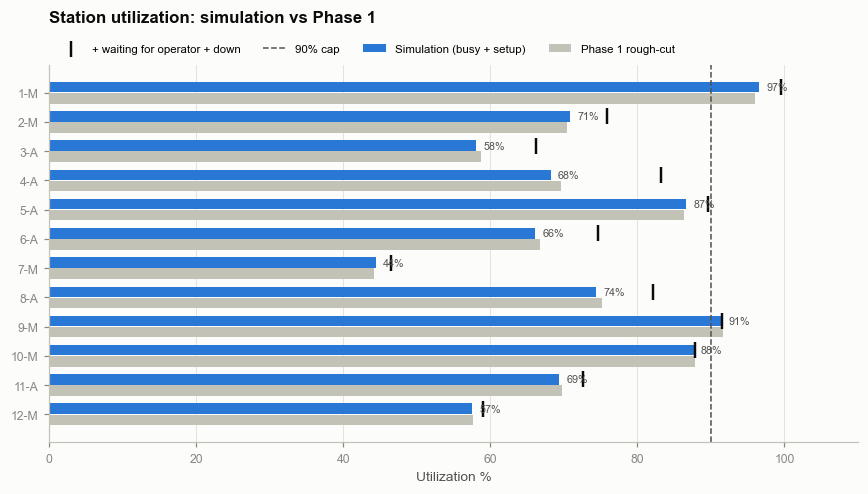

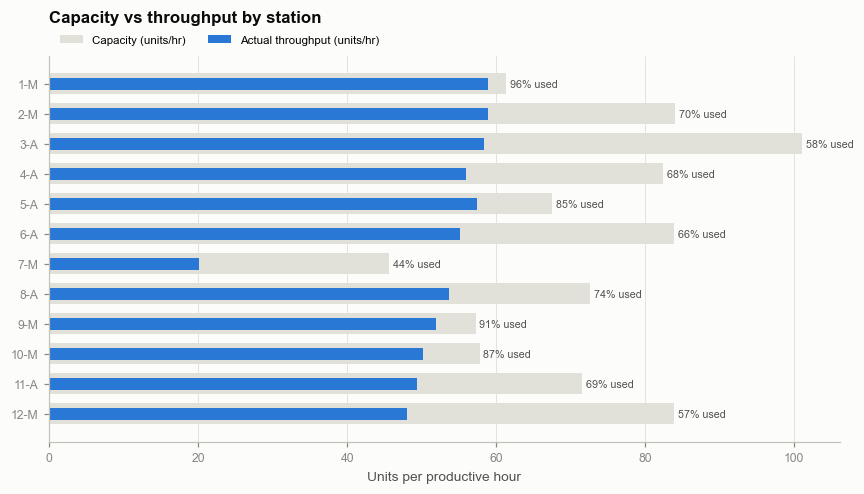

,Cell,Machines,Utilization,Busy %,Setup %,WaitOp %,Down %,Idle %,Capacity (units/hr),Throughput (units/hr),Avg queue,Max queue,Avg wait (min),Wait for operator (min/part),Group setups
Station,,,,,,,,,,,,,,,
1-M,Fab,2,0.966,0.960,0.006,0.030,0.000,0.004,61.332,58.857,13.986,47.000,14.258,0.061,13
2-M,Fab,2,0.708,0.701,0.008,0.050,0.001,0.241,83.978,58.857,0.439,22.000,0.448,0.101,13
3-A,Fab,2,0.580,0.578,0.003,0.075,0.006,0.338,101.043,58.397,0.306,27.000,0.315,0.154,43
4-A,Fab,1,0.682,0.679,0.003,0.140,0.010,0.168,82.383,55.938,1.932,62.000,2.072,0.150,43
5-A,Fab,6,0.867,0.852,0.015,0.023,0.007,0.104,67.506,57.467,3.285,77.000,3.430,0.119,43
6-A,Fab,3,0.661,0.657,0.004,0.073,0.012,0.254,83.916,55.150,1.052,46.000,1.145,0.237,13
7-M,Fab,1,0.444,0.439,0.005,0.020,0.001,0.535,45.605,20.032,0.057,7.000,0.170,0.059,13
8-A,Fab,2,0.743,0.740,0.004,0.072,0.006,0.179,72.631,53.642,1.980,79.000,2.215,0.160,43
9-M,Asm,6,0.914,0.912,0.002,0.002,0.000,0.084,57.228,51.877,4.341,58.000,5.020,0.010,13


In [6]:
P.plot_utilization(res); plt.show()
P.plot_capacity(res); plt.show()
display(res.stations[["Cell", "Machines", "Utilization", "Busy %", "Setup %", "WaitOp %", "Down %", "Idle %",
                      "Capacity (units/hr)", "Throughput (units/hr)", "Avg queue", "Max queue", "Avg wait (min)",
                      "Wait for operator (min/part)", "Group setups"]])


## 6. Machine states and individual machines

The station chart aggregates parallel machines. The heatmap and machine chart expose uneven loading. During a group setup, all participating machines are in Setup; while the setup team is being acquired, they are in Waiting for operator.

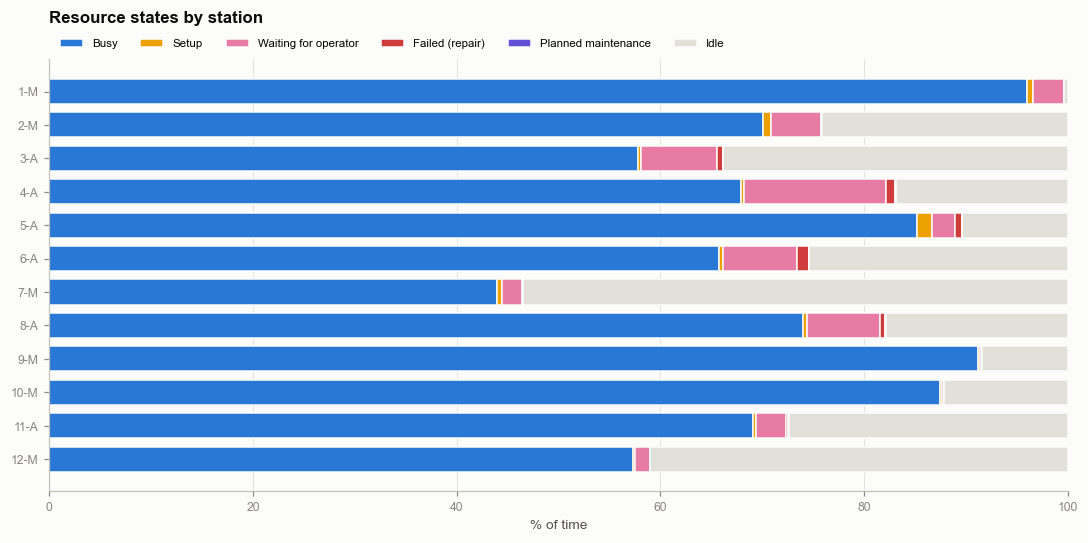

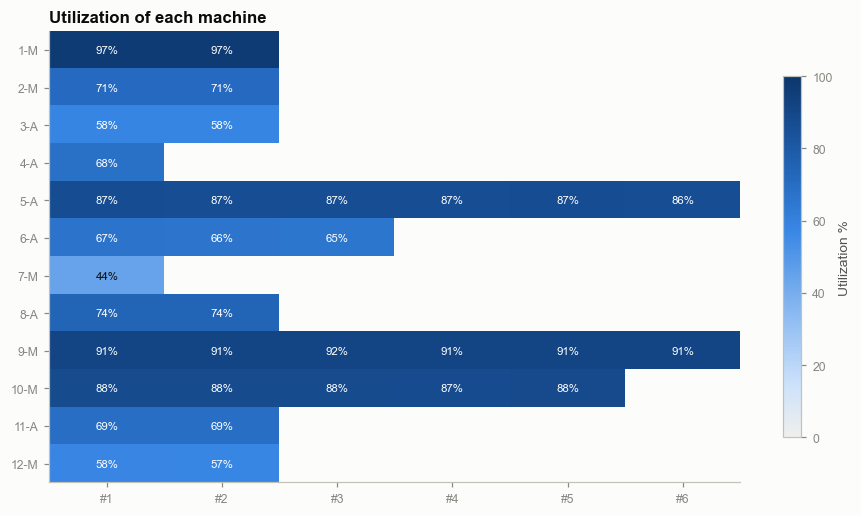

In [7]:
P.plot_machine_states(res, by="station"); plt.show()
P.plot_machine_heatmap(res); plt.show()


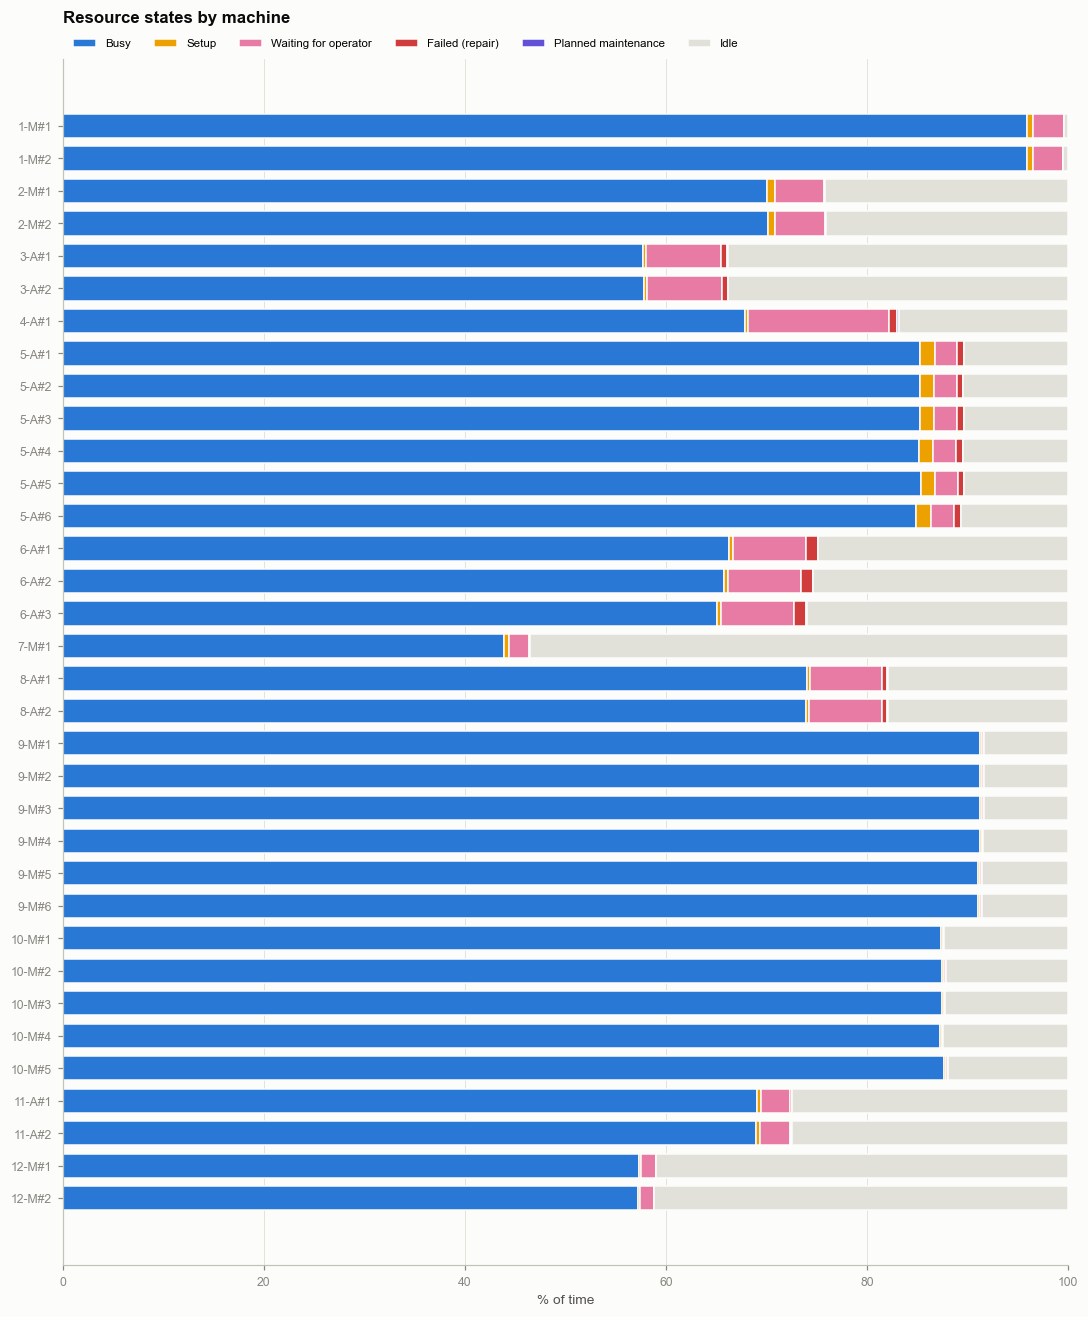

,Station,Busy %,Setup %,WaitOp %,Idle %,Failed %,PM %,Utilization,Units,Setups,Failures,PMs
Machine,,,,,,,,,,,,
1-M#1,1-M,0.960,0.006,0.030,0.004,0.000,0.000,0.966,17641,13,0,0
1-M#2,1-M,0.960,0.006,0.030,0.004,0.000,0.000,0.966,17673,13,0,0
2-M#1,2-M,0.701,0.008,0.049,0.242,0.001,0.000,0.708,17642,13,4,0
2-M#2,2-M,0.701,0.008,0.050,0.240,0.001,0.000,0.709,17672,13,4,0
3-A#1,3-A,0.577,0.003,0.075,0.339,0.006,0.000,0.580,17542,43,7,1
3-A#2,3-A,0.578,0.003,0.075,0.338,0.006,0.000,0.581,17496,43,7,1
4-A#1,4-A,0.679,0.003,0.140,0.168,0.008,0.002,0.682,33563,43,5,3
5-A#1,5-A,0.853,0.015,0.023,0.104,0.007,0.000,0.867,5852,43,2,0
5-A#2,5-A,0.853,0.015,0.022,0.104,0.007,0.000,0.867,5709,43,2,0


In [8]:
P.plot_machine_states(res, by="machine"); plt.show()
display(res.machines)


## 7. Operator workload and activity

Setup crews draw from the same cell operator pools used for normal processing. Daily busy-operator plots show demand against staffing. Gantt charts show the first four logged hours after warm-up, with colors indicating station assignment; simultaneous team assignments appear on multiple operator rows.

,Crew per shift,Avg busy,Peak busy,Utilization,Avg WIP in cell,Avg wait for operator (min/part),Avg wait for machine (min/part)
Cell,,,,,,,
Fab,7,6.199,7.000,0.886,38.139,0.135,3.304
Asm,13,11.380,13.000,0.875,17.675,0.032,1.564


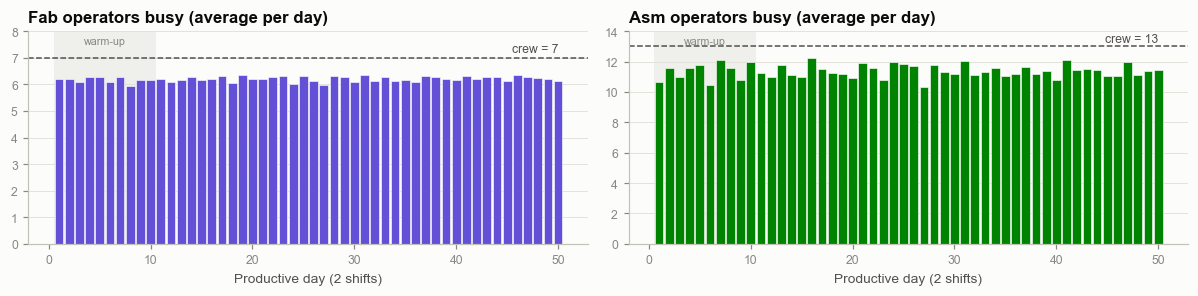

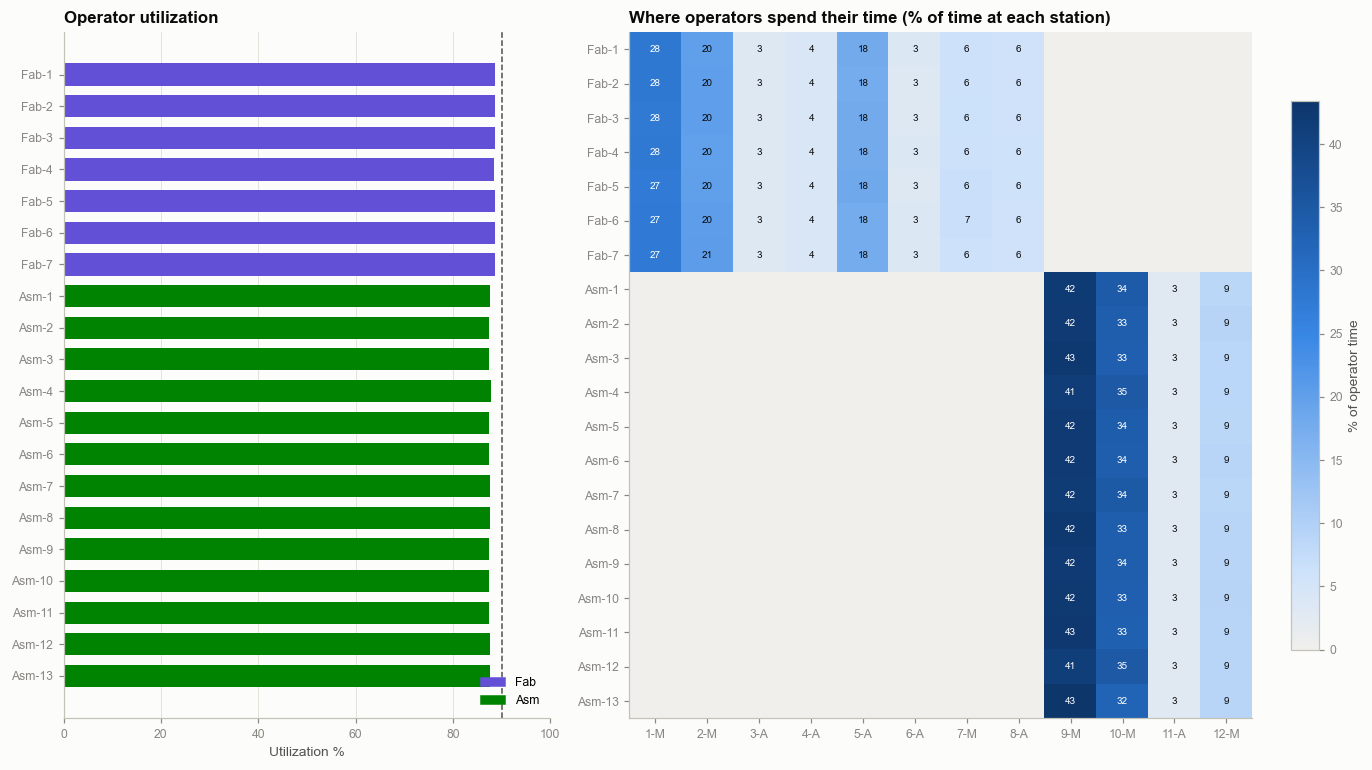

,Cell,Busy (hr),Utilization,Main station,1-M hr,2-M hr,3-A hr,4-A hr,5-A hr,6-A hr,7-M hr,8-A hr,9-M hr,10-M hr,11-A hr,12-M hr
Fab-1,Fab,531.554,0.886,1-M,167.400,120.700,18.800,24.400,107.200,20.400,37.300,35.500,0.000,0.000,0.000,0.000
Fab-2,Fab,531.380,0.886,1-M,167.200,122.000,19.100,24.600,105.600,20.100,37.200,35.600,0.000,0.000,0.000,0.000
Fab-3,Fab,531.409,0.886,1-M,165.800,121.400,19.100,24.400,107.300,19.900,38.100,35.600,0.000,0.000,0.000,0.000
Fab-4,Fab,530.489,0.884,1-M,166.000,119.200,18.800,24.400,107.600,20.500,37.600,36.300,0.000,0.000,0.000,0.000
Fab-5,Fab,531.398,0.886,1-M,163.000,120.800,19.100,24.000,109.400,20.300,39.000,35.700,0.000,0.000,0.000,0.000
Fab-6,Fab,531.412,0.886,1-M,164.600,122.600,19.000,24.300,105.800,20.500,39.600,35.000,0.000,0.000,0.000,0.000
Fab-7,Fab,531.387,0.886,1-M,164.900,123.500,19.200,24.300,105.800,20.700,37.500,35.500,0.000,0.000,0.000,0.000
Asm-1,Asm,525.276,0.875,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,251.700,205.800,16.600,51.200
Asm-2,Asm,524.236,0.874,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,252.500,200.600,16.900,54.200
Asm-3,Asm,524.455,0.874,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,255.400,199.500,16.600,52.900


In [9]:
display(res.cells)
P.plot_operators_busy(res); plt.show()
P.plot_operators(res); plt.show()
display(res.operators.join((res.op_station / 60).round(1).add_suffix(" hr")))


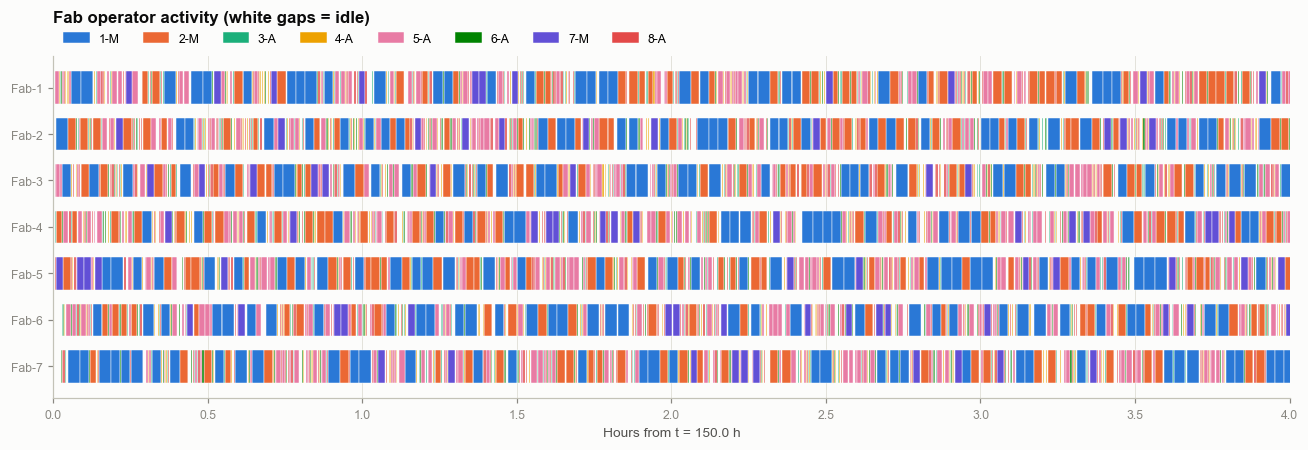

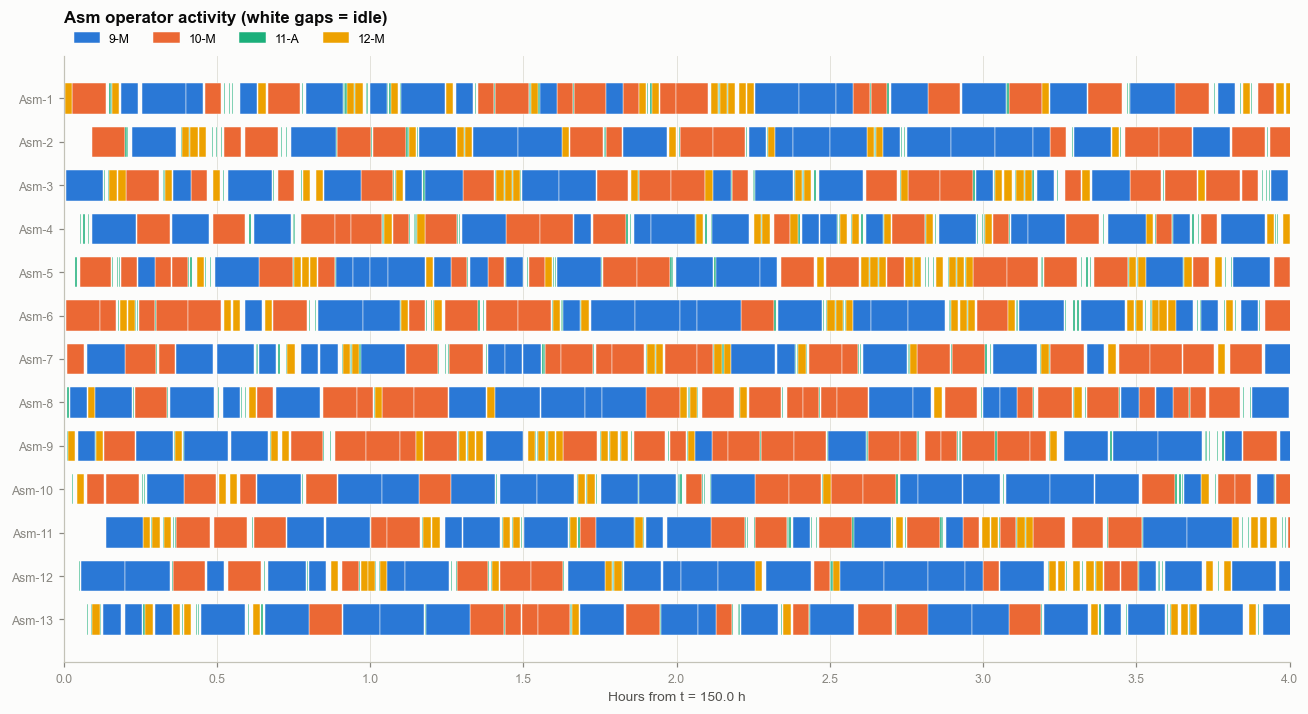

In [10]:
P.plot_operator_gantt(res, cell="Fab", hours=4); plt.show()
P.plot_operator_gantt(res, cell="Asm", hours=4); plt.show()


## 8. Station-group setups and team labor

Group setups count whole-station events during the measurement window. Machine setups count each participating machine: one event at 5-A contributes six machine setups. The event table and crew chart use the first logged week after warm-up; the event-count chart uses the complete eight-week measurement period.

,Station,Lot,Model,Start,End,Crew,Elapsed min,Operator min
0,1-M,15,M860,"10,590.502","10,607.169",2,16.667,33.333
1,1-M,18,M860,"13,237.041","13,253.708",2,16.667,33.333
2,10-M,15,M860,"10,681.219","10,686.775",5,5.556,27.778
3,10-M,18,M860,"13,328.851","13,334.407",5,5.556,27.778
4,11-A,13,M1080,"9,639.749","9,643.499",2,3.750,7.500
5,11-A,14,M970,"9,745.804","9,748.304",2,2.500,5.000
6,11-A,15,M860,"10,689.933","10,692.433",2,2.500,5.000
7,11-A,16,M1080,"12,032.252","12,036.002",2,3.750,7.500
8,11-A,17,M970,"12,162.324","12,164.824",2,2.500,5.000
9,11-A,18,M860,"13,337.565","13,340.065",2,2.500,5.000


,Machines,Group setups,Setups,Setup %,WaitOp %
Station,,,,,
1-M,2,13,26,0.006,0.030
2-M,2,13,26,0.008,0.050
3-A,2,43,86,0.003,0.075
4-A,1,43,43,0.003,0.140
5-A,6,43,258,0.015,0.023
6-A,3,13,39,0.004,0.073
7-M,1,13,13,0.005,0.020
8-A,2,43,86,0.004,0.072
9-M,6,13,78,0.002,0.002


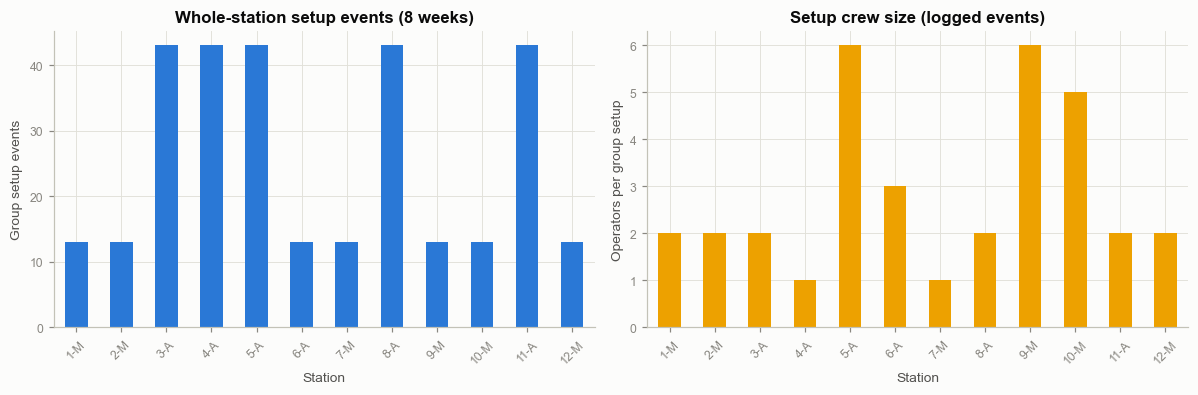

In [11]:
setup_tasks = res.op_log[res.op_log.Task == "setup"].copy()
events = pd.DataFrame()
if not setup_tasks.empty:
    events = setup_tasks.groupby(["Station", "Lot", "Model", "Start", "End"]).agg(Crew=("Operator", "nunique")).reset_index()
    events["Elapsed min"] = events.End - events.Start
    events["Operator min"] = events["Elapsed min"] * events.Crew
    display(events.head(25))
display(res.stations[["Machines", "Group setups", "Setups", "Setup %", "WaitOp %"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
res.stations["Group setups"].reindex(STATIONS).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_title("Whole-station setup events (8 weeks)")
axes[0].set_ylabel("Group setup events")
if not events.empty:
    observed = events.groupby("Station").Crew.mean().reindex(STATIONS)
    observed.plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_title("Setup crew size (logged events)")
axes[1].set_ylabel("Operators per group setup")
fig.tight_layout(); plt.show()


## 9. Scrap, spare components, and lot completion

Scrap is measured per entity: a kit, component, or assembled display. Unneeded branch outputs are counted as spare; unmatched components left when their accounting group closes are counted separately. EOQ identifiers are accounting and matching groups, not station processing restrictions.

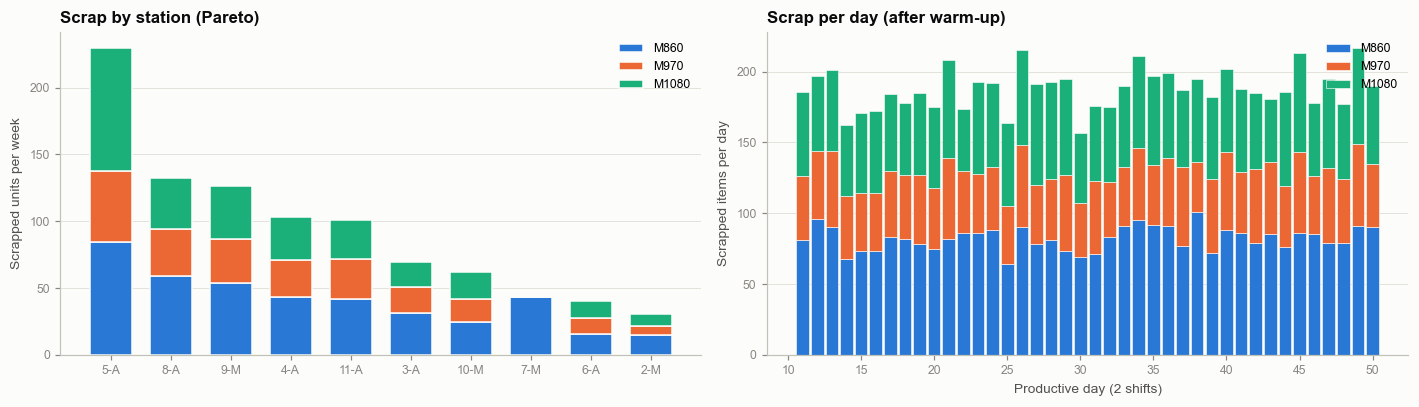

Units per week  Invested_min per week  Labor_dollars per week
Station Item                         Model                                                               
10-M    Display assembly             M1080          19.800                796.600                 156.600
                                     M860           24.900                551.300                 129.200
                                     M970           17.200                586.400                 119.500
11-A    Display assembly             M1080          29.500              1,242.200                 239.300
                                     M860           41.600                992.300                 211.900
                                     M970           30.000              1,067.200                 212.200
2-M     LCD/PCB set                  M1080           9.200                 36.400                   9.400
                                     M860           15.000                 43.200                  11.100
                                     M970            6.400                 21.700                   5.600
3-A     Power strip/PCB/LCD sub-assy M1080          18.800                105.400                  20.600
                                     M860           31.000                106.700                  24.700
                                     M970           20.000                 96.100                  18.700
4-A     Keyboard sub-assy            M1080          32.500                 96.400                  21.400
                                     M860           43.500                117.900                  25.200
                                     M970           27.500                 64.200                  14.300
5-A     Power strip/PCB/LCD sub-assy M1080          92.400              1,189.300                 135.000
                                     M860           84.600                519.400                  98.100
                                     M970           53.000                596.900                  68.700
6-A     Backlight/sensor sub-assy    M1080          12.800                 92.400                  14.000
                                     M860           15.500                 63.900                  12.300
                                     M970           12.200                 65.700                  11.400
7-M     Display assembly             M860           43.100                616.000                 123.200
8-A     Display assembly             M1080          38.500                968.600                 129.900
                                     M860           58.800                918.500                 182.800
                                     M970           35.400                725.800                 101.700
9-M     Display assembly             M1080          39.500              1,335.100                 235.700
                                     M860           53.600              1,019.200                 224.100
                                     M970           33.400                927.400                 176.400

,EOQ,Kits,Finished,Finished / EOQ,Short of EOQ,Scrapped,Spare,Unmatched,Yield (finished / kits),Planned yield,Lot flow time (hr)
Model,,,,,,,,,,,
M1080,655.000,785.000,651.722,0.995,4.111,154.278,92.389,14.333,0.830,0.835,40.516
M860,754.000,963.000,751.625,0.997,5.500,243.250,105.938,14.438,0.781,0.783,44.493
M970,596.000,699.000,591.056,0.992,6.167,124.889,58.889,11.889,0.846,0.853,41.009


In [12]:
P.plot_scrap(res); plt.show()
weeks = res.T / 4500
scr = res.scrap.groupby(["Station", "Item", "Model"]).agg(Units=("Part", "count"),
    Invested_min=("Invested min", "sum"), Labor_dollars=("Labor $", "sum"))
display((scr / weeks).round(1).rename(columns=lambda c: c + " per week"))
lots = res.lots.dropna(subset=["Done"])
display(lots.groupby("Model")[["EOQ", "Kits", "Finished", "Finished / EOQ", "Short of EOQ", "Scrapped", "Spare",
    "Unmatched", "Yield (finished / kits)", "Planned yield", "Lot flow time (hr)"]].mean())


## 10. Individual-display flow time

Flow time starts at the actual arrival of the oldest constituent kit and ends at finished-display departure. It includes setup, queues, matching, downtime, and processing. The distribution is distinct from whole-lot completion time.

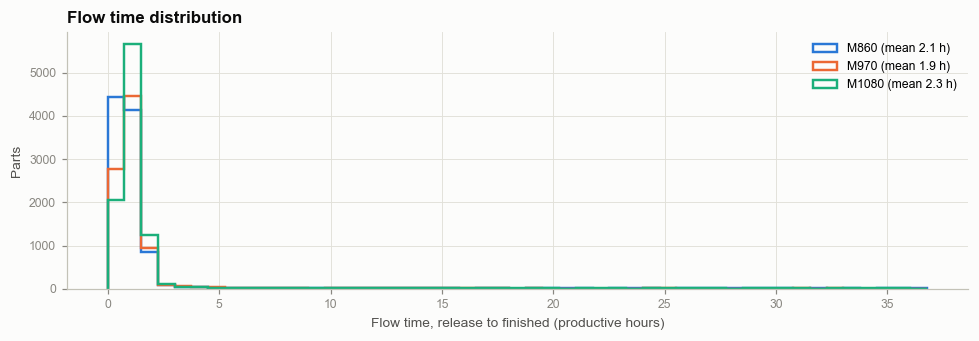

,Avg flow time (hr),P90 flow time (hr)
Model,,
M860,2.133,1.804
M970,1.883,1.825
M1080,2.266,1.971
Total,2.102,1.881


In [13]:
P.plot_flow_time(res); plt.show()
display(res.throughput[["Avg flow time (hr)", "P90 flow time (hr)"]])


## 11. Replications and policy comparisons

Compares four release policies with the same total kit rate: continuous product runs (the default), the cyclic 1-2-3 rotation with per-machine changeovers, the cyclic rotation with workcell setups (`phase2_assumptions_simulation.ipynb`), and the heijunka sequence with workcell setups (this notebook). Check the per-model rows: cyclic meets total demand while under-building M860 and over-building M970. Each policy uses ten replications with seeds 1–10. Reported half-widths are 95% confidence intervals for the mean.

In [14]:
policies = {
    "Continuous product runs": get_scenario(YEAR, release_mode="continuous"),
    "Unit rotation: machine changeovers": get_scenario(YEAR, release_mode="cyclic"),
    "Unit rotation: assumptions": get_scenario(YEAR, release_mode="cyclic", setup_scope="workcell",
                                               setup_crew=SETUP_CREW),
    "Heijunka + workcell": sc,
}
summaries = {}
for name, scenario in policies.items():
    print("Running:", name, flush=True)
    _, summaries[name] = run_replications(scenario, n=N_REPS, n_jobs=N_JOBS)
keys = [
    ("WIP", "Average WIP (parts)"), ("WIP", "Ending WIP (parts)"),
    ("Throughput", "Total per week"), ("Throughput", "% of demand"),
    *[("Throughput", f"{model} per week") for model in MODELS],
    *[("Flow time (hr)", model) for model in MODELS],
    ("Operators", "Fab utilization"), ("Operators", "Asm utilization"),
]
comparison = pd.concat([summary.loc[keys, "Average"].rename(name) for name, summary in summaries.items()], axis=1)
display(comparison)

# Each model's weekly output as a share of its own weekly demand
demand_wk = {m: sc.demand[m] / 50 for m in MODELS}
by_model = pd.DataFrame({name: {m: s.loc[("Throughput", f"{m} per week"), "Average"] / demand_wk[m]
                                for m in MODELS} for name, s in summaries.items()})
display(by_model.style.format("{:.1%}").set_caption("Output as % of each model's demand"))

assumptions_summary = summaries["Heijunka + workcell"]
display(assumptions_summary.loc[keys, ["Average", "Half Width", "Minimum", "Maximum"]])
comparison.to_csv("heijunka_comparison.csv")

Running: Continuous product runs
Running: Unit rotation: machine changeovers
Running: Unit rotation: assumptions
Running: Heijunka + workcell


Continuous product runs  Unit rotation: machine changeovers  Unit rotation: assumptions  Heijunka + workcell
Category       Statistic                                                                                                                        
WIP            Average WIP (parts)                  984.301                          20,939.207                     200.230              191.629
               Ending WIP (parts)                   772.100                          34,786.000                     166.800              152.900
Throughput     Total per week                     3,608.812                             870.300                   3,615.912            3,601.938
               % of demand                            0.999                               0.241                       1.001                0.997
               M860 per week                      1,312.088                             276.375                   1,147.312            1,273.412
               M970 per week                      1,110.263                             300.175                   1,249.075            1,103.362
               M1080 per week                     1,186.463                             293.750                   1,219.525            1,225.162
Flow time (hr) M860                                  14.828                             349.612                       2.262                2.042
               M970                                  15.406                             348.600                       1.909                1.879
               M1080                                 13.784                             349.027                       2.368                2.265
Operators      Fab utilization                        0.885                               0.885                       0.881                0.885
               Asm utilization                        0.872                               0.259                       0.895                0.876

,Continuous product runs,Unit rotation: machine changeovers,Unit rotation: assumptions,Heijunka + workcell
M860,102.7%,21.6%,89.8%,99.7%
M970,100.4%,27.1%,112.9%,99.8%
M1080,96.4%,23.9%,99.1%,99.6%


Average  Half Width   Minimum   Maximum
Category       Statistic                                                    
WIP            Average WIP (parts)   191.629       2.255   185.595   195.470
               Ending WIP (parts)    152.900      18.733   115.000   205.000
Throughput     Total per week      3,601.938       4.402 3,593.125 3,611.500
               % of demand             0.997       0.001     0.994     0.999
               M860 per week       1,273.412       3.476 1,266.750 1,280.500
               M970 per week       1,103.362       2.785 1,097.250 1,108.250
               M1080 per week      1,225.162       3.036 1,219.750 1,231.500
Flow time (hr) M860                    2.042       0.042     1.954     2.133
               M970                    1.879       0.032     1.823     1.950
               M1080                   2.265       0.041     2.181     2.375
Operators      Fab utilization         0.885       0.000     0.885     0.886
               Asm utilization         0.876       0.001     0.874     0.878

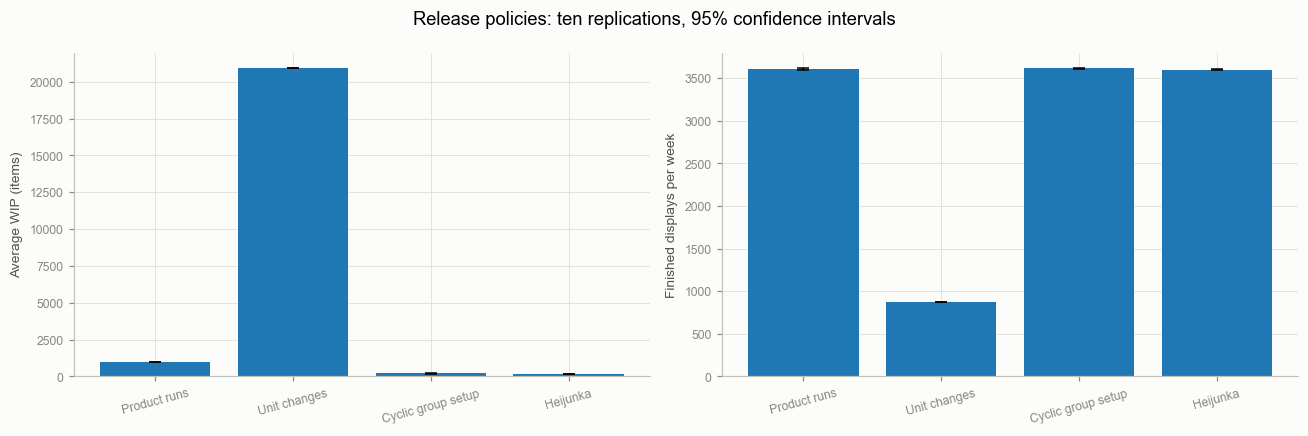

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, label in zip(axes, [("WIP", "Average WIP (parts)"), ("Throughput", "Total per week")],
                         ["Average WIP (items)", "Finished displays per week"]):
    means = [summary.loc[key, "Average"] for summary in summaries.values()]
    errors = [summary.loc[key, "Half Width"] for summary in summaries.values()]
    ax.bar(["Product runs", "Unit changes", "Cyclic group setup", "Heijunka"], means, yerr=errors, capsize=4)
    ax.tick_params(axis="x", labelrotation=15)
    ax.set_ylabel(label)
fig.suptitle("Release policies: ten replications, 95% confidence intervals")
fig.tight_layout(); plt.show()

## 12. Bottlenecks across replications

Station utilization and average queues are averaged across the heijunka + workcell replications. High utilization and persistent queues identify constraints; machine Setup and Waiting for operator states explain capacity losses.

,Avg utilization (10 reps),Avg queue (10 reps),Machines,Setup %,WaitOp %,Group setups
Statistic,,,,,,
1-M,0.966,13.963,2,0.006,0.030,13
9-M,0.915,4.120,6,0.002,0.002,13
10-M,0.877,0.487,5,0.002,0.002,13
5-A,0.866,3.221,6,0.015,0.023,43
8-A,0.744,1.947,2,0.004,0.072,43
2-M,0.708,0.441,2,0.008,0.050,13
11-A,0.693,0.351,2,0.004,0.029,43
4-A,0.682,1.932,1,0.003,0.140,43
6-A,0.661,0.811,3,0.004,0.073,13


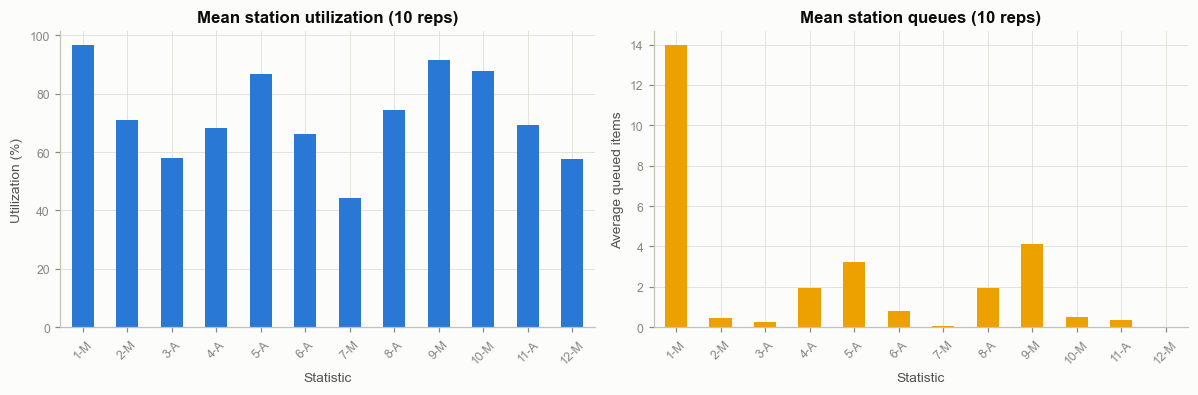

Average  Half Width   Minimum   Maximum
Category            Statistic                                                                    
Throughput          M860 per week                       1,273.412       3.476 1,266.750 1,280.500
                    M970 per week                       1,103.362       2.785 1,097.250 1,108.250
                    M1080 per week                      1,225.162       3.036 1,219.750 1,231.500
                    Total per week                      3,601.938       4.402 3,593.125 3,611.500
                    % of demand                             0.997       0.001     0.994     0.999
Flow time (hr)      M860                                    2.042       0.042     1.954     2.133
                    M970                                    1.879       0.032     1.823     1.950
                    M1080                                   2.265       0.041     2.181     2.375
WIP                 Average WIP (parts)                   191.629       2.255   185.595   195.470
                    Ending WIP (parts)                    152.900      18.733   115.000   205.000
Operators           Fab utilization                         0.885       0.000     0.885     0.886
                    Fab wait for operator (min/part)        0.135       0.000     0.134     0.136
                    Asm utilization                         0.876       0.001     0.874     0.878
                    Asm wait for operator (min/part)        0.032       0.000     0.031     0.033
Station utilization 1-M                                     0.966       0.000     0.966     0.966
                    2-M                                     0.708       0.000     0.708     0.708
                    3-A                                     0.581       0.000     0.580     0.581
                    4-A                                     0.682       0.000     0.682     0.682
                    5-A                                     0.866       0.000     0.866     0.867
                    6-A                                     0.661       0.000     0.661     0.661
                    7-M                                     0.443       0.001     0.442     0.444
                    8-A                                     0.744       0.000     0.743     0.745
                    9-M                                     0.915       0.001     0.913     0.917
                    10-M                                    0.877       0.001     0.874     0.879
                    11-A                                    0.693       0.001     0.691     0.695
                    12-M                                    0.575       0.001     0.573     0.576
Avg queue           1-M                                    13.963       0.129    13.581    14.223
                    2-M                                     0.441       0.003     0.433     0.448
                    3-A                                     0.242       0.032     0.201     0.323
                    4-A                                     1.932       0.033     1.862     2.018
                    5-A                                     3.221       0.178     2.696     3.599
                    6-A                                     0.811       0.138     0.496     1.052
                    7-M                                     0.056       0.002     0.051     0.058
                    8-A                                     1.947       0.078     1.793     2.118
                    9-M                                     4.120       0.220     3.492     4.488
                    10-M                                    0.487       0.006     0.468     0.499
                    11-A                                    0.351       0.023     0.309     0.426
                    12-M                                    0.008       0.000     0.007     0.009
Down %              1-M                                     0.000       0.000     0.000     0.000
                    2-M                 

In [16]:
summary = assumptions_summary
avg_util = summary.xs("Station utilization").Average.rename("Avg utilization (10 reps)")
avg_q = summary.xs("Avg queue").Average.rename("Avg queue (10 reps)")
bottlenecks = pd.concat([avg_util, avg_q], axis=1).join(res.stations[["Machines", "Setup %", "WaitOp %", "Group setups"]])
display(bottlenecks.sort_values("Avg utilization (10 reps)", ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
avg_util.reindex(STATIONS).mul(100).plot.bar(ax=axes[0], color="#2a78d6", rot=45)
axes[0].set_ylabel("Utilization (%)")
axes[0].set_title("Mean station utilization (10 reps)")
avg_q.reindex(STATIONS).plot.bar(ax=axes[1], color="#eda100", rot=45)
axes[1].set_ylabel("Average queued items")
axes[1].set_title("Mean station queues (10 reps)")
fig.tight_layout(); plt.show()
display(summary)
